# Proyecto final · Machine Learning · Universidad EIA
## Predicción de retrasos de llegada en vuelos de EE. UU. (mayo 2025 – mayo 2026)

**Problema:** dado un vuelo programado, ¿llegará con **15 minutos o más de retraso**? La predicción se hace **al momento de la salida programada**, usando solo lo que ya se sabe en ese instante (itinerario, congestión programada y cómo venía la aeronave en su tramo anterior).

Ruta: **1 ¿ML?** · **2 Datos** · **3 Limpieza** · **4 Columnas** · **5 Modelos** · **6 Evaluación**

> Este es el **único notebook** del proyecto. Corre de principio a fin con `Kernel → Restart & Run All`.
> Para la exposición en vivo dejen `MODO_RAPIDO = True` (unos pocos minutos). Para los números finales del informe, `MODO_RAPIDO = False`.

In [23]:
import warnings, re, time, json, shutil
warnings.filterwarnings("ignore")

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pandas.api.types import union_categoricals
from pandas.tseries.holiday import USFederalHolidayCalendar

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (HistGradientBoostingClassifier,
                              HistGradientBoostingRegressor,
                              RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.impute import SimpleImputer

try:
    from xgboost import XGBClassifier
    HAY_XGB = True
except ImportError:
    HAY_XGB = False
    print("xgboost no está instalado: se omite ese modelo (pip install xgboost).")

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 60)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})

xgboost no está instalado: se omite ese modelo (pip install xgboost).


### Configuración (todo lo que se puede cambiar está aquí)

In [9]:
# ----------------------------- PARÁMETROS -----------------------------
SEMILLA = 42                      # semilla fija: los números coinciden con las láminas
MODO_RAPIDO = True                # True = muestra reducida (exposición en vivo) · False = corrida final
DESDE, HASTA = (2025, 5), (2026, 5)   # periodo del taller: mayo 2025 a mayo 2026 (año, mes)
DESCARGAR = True                  # True = baja los CSV con kagglehub si no están en datos/crudos
KAGGLE_ID = "umerhafeezsiddiqui/2021-2026-us-flights"
FRACCION_PRUEBA = 0.15            # el último 15 % del tiempo (~2 meses) queda como prueba final
UMBRAL_RETRASO = 15               # minutos de retraso en llegada que cuentan como "retrasado"

# Tamaños de muestra (filas): CV = comparar modelos · FINAL = entrenar el elegido · TEST = prueba temporal
if MODO_RAPIDO:
    N_CV, N_FINAL, N_TEST = 60_000, 150_000, 150_000
else:
    N_CV, N_FINAL, N_TEST = 400_000, 2_000_000, 1_000_000
K_FOLDS = 3 if MODO_RAPIDO else 5

# ------------------------------- RUTAS --------------------------------
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATOS   = RAIZ / "datos" / "crudos"
PROC    = RAIZ / "datos" / "procesados"
MODELOS = RAIZ / "modelos"
RES     = RAIZ / "resultados"
FIG     = RES / "figuras"
for carpeta in (DATOS, PROC, MODELOS, RES, FIG):
    carpeta.mkdir(parents=True, exist_ok=True)

rng = np.random.default_rng(SEMILLA)
np.random.seed(SEMILLA)

def guardar_fig(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight")

print("Raíz del proyecto:", RAIZ)
print("Modo:", "RÁPIDO" if MODO_RAPIDO else "COMPLETO", "| muestras CV/FINAL/TEST =", N_CV, N_FINAL, N_TEST)

Raíz del proyecto: c:\Users\HP\Desktop\Proyecto-final-Machine-Learning
Modo: RÁPIDO | muestras CV/FINAL/TEST = 60000 150000 150000


## 1 · ¿Hace falta ML?

| Pregunta | Respuesta |
|---|---|
| ¿Hay un patrón que aprender? | **Sí.** El retraso depende de la hora del día, del aeropuerto, de la aerolínea, de la congestión programada y de si la aeronave viene retrasada de su tramo anterior (esto último se verifica en el paso 4). |
| ¿Hay etiqueta? | **Sí.** `ARR_DEL15` ya viene en los datos (retraso de llegada ≥ 15 min). No hay que inventarla. |
| ¿Hay suficientes datos? | **Sí**, más de 8 millones de vuelos en 13 meses (se confirma al cargar, en el paso 2). |
| ¿Una regla a mano ya basta? | **Se mide, no se supone.** La regla de una persona sin ML sería *«los vuelos de la tarde-noche se retrasan»*. Se calcula en el paso 5 y el modelo debe ganarle con margen. |
| ¿Cuánto cuesta equivocarse? | Un **falso negativo** (no avisar un retraso) hace que el pasajero pierda una conexión o la aerolínea no reprograme tripulación. Un **falso positivo** genera una alerta innecesaria. El primero cuesta más, por eso se mira el **recall** y el **F1**, no solo la exactitud. |

**Veredicto:** vale la pena intentar ML **si y solo si** supera con margen a la línea base (siempre «a tiempo») y a la regla a mano. Si no, gana la regla. Se decide en el paso 6.

**¿Por qué vale la pena predecirla?** Con la predicción a la hora de salida, la aerolínea puede reasignar puertas y tripulación, y el pasajero puede reorganizar su conexión antes de llegar al aeropuerto de destino.

## 2 · Los datos: la ficha

- **Página:** https://www.kaggle.com/datasets/umerhafeezsiddiqui/2021-2026-us-flights
- **Quién publica los datos:** usuario de Kaggle `umerhafeezsiddiqui`. Los nombres de columnas (`FL_DATE`, `OP_UNIQUE_CARRIER`, `ARR_DEL15`, `CRS_DEP_TIME`…) son los del reporte *On-Time Performance* del Bureau of Transportation Statistics (US DOT). ✍️ **Verifiquen en la sección *About/Provenance* de la página la fuente declarada y la licencia, y cópienlas en `docs/01_ficha_de_datos.txt`.**
- **Cómo se descargan:** con `kagglehub` (la celda de abajo), un CSV por mes llamado `Mmm-AAAA.csv` (ej. `Jun-2025.csv`). Usamos los 13 archivos de `May-2025.csv` a `May-2026.csv`.
- **Qué es una fila:** un vuelo programado (un tramo origen → destino, de una aerolínea, en una fecha).
- **Etiqueta:** `retraso15` = el vuelo llegó con ≥ 15 min de retraso (`ARR_DEL15`).

In [10]:
DATOS = Path("../datos/crudos")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
df = pd.read_csv(DATOS / "Flights_2025_2026.csv")
print(df.shape)
df.head(6)

(8454288, 35)


,YEAR,MONTH,DAY_OF_MONTH,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN,DEST_AIRPORT_ID,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,S
0,2026,4,1,04-01-26 00:00,9E,N131EV,4969,15919,XNA,12953,LGA,1150,1258.0,68.0,1.0,24.0,1322.0,1649.0,7.0,1547,1656.0,69.0,1.0,0,0,177.0,178.0,147.0,1147,0.0,0.0,69.0,0.0,0.0,NaN
1,2026,4,1,04-01-26 00:00,9E,N131EV,5348,12953,LGA,13931,ORF,1633,1743.0,70.0,1.0,47.0,1830.0,1938.0,11.0,1803,1949.0,106.0,1.0,0,0,90.0,126.0,68.0,296,2.0,0.0,36.0,0.0,68.0,NaN
2,2026,4,1,04-01-26 00:00,9E,N131EV,5348,13931,ORF,12953,LGA,1843,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2012,NaN,NaN,NaN,1,0,89.0,NaN,NaN,296,NaN,NaN,NaN,NaN,NaN,NaN
3,2026,4,1,04-01-26 00:00,9E,N131EV,5402,11423,DSM,13487,MSP,655,646.0,-9.0,0.0,16.0,702.0,747.0,7.0,814,754.0,-20.0,0.0,0,0,79.0,68.0,45.0,232,NaN,NaN,NaN,NaN,NaN,NaN
4,2026,4,1,04-01-26 00:00,9E,N131EV,5536,13487,MSP,15919,XNA,904,911.0,7.0,0.0,27.0,938.0,1102.0,4.0,1109,1106.0,-3.0,0.0,0,0,125.0,115.0,84.0,596,NaN,NaN,NaN,NaN,NaN,NaN
5,2026,4,1,04-01-26 00:00,9E,N132EV,4699,10208,AGS,10397,ATL,650,639.0,-11.0,0.0,18.0,657.0,727.0,8.0,802,735.0,-27.0,0.0,0,0,72.0,56.0,30.0,143,NaN,NaN,NaN,NaN,NaN,NaN


### Eliminamos las variables con más del 50 % de datos nulos
Las columnas `S`, `CARRIER_DELAY`, `WEATHER_DELAY`, `NAS_DELAY`, `SECURITY_DELAY` y `LATE_AIRCRAFT_DELAY` (causas del retraso) solo se llenan cuando el vuelo **ya se retrasó**: además de estar casi vacías son **fuga de información**. Por eso ni siquiera entran a `df`: se descartaron al cargar. La lista se calcula sola:

In [11]:
nulos_tot = df.isnull().sum()
filas_tot = df.shape[0]

nulos_pct = (nulos_tot / filas_tot * 100).round(2).sort_values(ascending=False)

display(nulos_pct.to_frame("% nulos").head(16))


# 2. Identificar las columnas con más del 50 % de nulos
cols_mas_50 = nulos_pct[nulos_pct > 50].index.tolist()

print("Columnas con > 50 % de nulos (descartadas):", cols_mas_50)


# 3. Eliminar las columnas identificadas
df.drop(columns=cols_mas_50, inplace=True)


# 4. Mostrar las primeras 5 filas del DataFrame actualizado
display(df.head(5))


,% nulos
S,100.00
NAS_DELAY,77.93
SECURITY_DELAY,77.93
CARRIER_DELAY,77.93
WEATHER_DELAY,77.93
LATE_AIRCRAFT_DELAY,77.93
ARR_DELAY,2.08
ACTUAL_ELAPSED_TIME,2.08
AIR_TIME,2.08
ARR_DEL15,2.08


Columnas con > 50 % de nulos (descartadas): ['S', 'NAS_DELAY', 'SECURITY_DELAY', 'CARRIER_DELAY', 'WEATHER_DELAY', 'LATE_AIRCRAFT_DELAY']


,YEAR,MONTH,DAY_OF_MONTH,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN,DEST_AIRPORT_ID,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE
0,2026,4,1,04-01-26 00:00,9E,N131EV,4969,15919,XNA,12953,LGA,1150,1258.0,68.0,1.0,24.0,1322.0,1649.0,7.0,1547,1656.0,69.0,1.0,0,0,177.0,178.0,147.0,1147
1,2026,4,1,04-01-26 00:00,9E,N131EV,5348,12953,LGA,13931,ORF,1633,1743.0,70.0,1.0,47.0,1830.0,1938.0,11.0,1803,1949.0,106.0,1.0,0,0,90.0,126.0,68.0,296
2,2026,4,1,04-01-26 00:00,9E,N131EV,5348,13931,ORF,12953,LGA,1843,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2012,NaN,NaN,NaN,1,0,89.0,NaN,NaN,296
3,2026,4,1,04-01-26 00:00,9E,N131EV,5402,11423,DSM,13487,MSP,655,646.0,-9.0,0.0,16.0,702.0,747.0,7.0,814,754.0,-20.0,0.0,0,0,79.0,68.0,45.0,232
4,2026,4,1,04-01-26 00:00,9E,N131EV,5536,13487,MSP,15919,XNA,904,911.0,7.0,0.0,27.0,938.0,1102.0,4.0,1109,1106.0,-3.0,0.0,0,0,125.0,115.0,84.0,596


In [25]:
imputer_median = SimpleImputer(strategy='median')
imputer_mode = SimpleImputer(strategy='most_frequent')

COLS_NUM_NUL= ["WHEELS_ON","WHEELS_OFF", "TAXI_OUT", "ARR_TIME", "TAXI_IN",
            "AIR_TIME", "ACTUAL_ELAPSED_TIME", "ARR_DELAY", "ARR_DEL15","DEP_DELAY"]

# Rellenar los nulos de cada columna numérica con su mediana
for col in COLS_NUM_NUL:
    df[[col]] = imputer_median.fit_transform(df[[col]])

display(df[COLS_NUM_NUL].head())
display(df.head(5))

,WHEELS_ON,WHEELS_OFF,TAXI_OUT,ARR_TIME,TAXI_IN,AIR_TIME,ACTUAL_ELAPSED_TIME,ARR_DELAY,ARR_DEL15,DEP_DELAY
0,1649.0,1322.0,24.0,1656.0,7.0,147.0,178.0,69.0,1.0,68.0
1,1938.0,1830.0,47.0,1949.0,11.0,68.0,126.0,106.0,1.0,70.0
2,1458.0,1337.0,16.0,1502.0,7.0,94.0,123.0,-6.0,0.0,-2.0
3,747.0,702.0,16.0,754.0,7.0,45.0,68.0,-20.0,0.0,-9.0
4,1102.0,938.0,27.0,1106.0,4.0,84.0,115.0,-3.0,0.0,7.0


,YEAR,MONTH,DAY_OF_MONTH,FL_DATE,OP_UNIQUE_CARRIER,TAIL_NUM,OP_CARRIER_FL_NUM,ORIGIN_AIRPORT_ID,ORIGIN,DEST_AIRPORT_ID,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,DEP_DEL15,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,ARR_DEL15,CANCELLED,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,tiene_etiqueta,fecha,hora_sal,hora_sal_dec,hora_lleg,dia_semana,dias_a_festivo
0,2026,4,1,04-01-26 00:00,9E,N131EV,4969,15919,XNA,12953,LGA,1150,1258.0,68.0,1.0,24.0,1322.0,1649.0,7.0,1547,1656.0,69.0,1.0,0,0,177,178.0,147.0,1147,True,2026-04-01,11,11.8333,15,2,7
1,2026,4,1,04-01-26 00:00,9E,N131EV,5348,12953,LGA,13931,ORF,1633,1743.0,70.0,1.0,47.0,1830.0,1938.0,11.0,1803,1949.0,106.0,1.0,0,0,90,126.0,68.0,296,True,2026-04-01,16,16.5500,18,2,7
2,2026,4,1,04-01-26 00:00,9E,N131EV,5348,13931,ORF,12953,LGA,1843,NaN,-2.0,NaN,16.0,1337.0,1458.0,7.0,2012,1502.0,-6.0,0.0,1,0,89,123.0,94.0,296,False,2026-04-01,18,18.7167,20,2,7
3,2026,4,1,04-01-26 00:00,9E,N131EV,5402,11423,DSM,13487,MSP,655,646.0,-9.0,0.0,16.0,702.0,747.0,7.0,814,754.0,-20.0,0.0,0,0,79,68.0,45.0,232,True,2026-04-01,6,6.9167,8,2,7
4,2026,4,1,04-01-26 00:00,9E,N131EV,5536,13487,MSP,15919,XNA,904,911.0,7.0,0.0,27.0,938.0,1102.0,4.0,1109,1106.0,-3.0,0.0,0,0,125,115.0,84.0,596,True,2026-04-01,9,9.0667,11,2,7


## 3 · Limpieza

Cada decisión se imprime con su conteo para poder justificarla en la exposición.

### 3.1 Horarios programados inválidos
Sin hora programada, duración o distancia no hay vuelo que predecir.

In [12]:
criticas = ["CRS_DEP_TIME", "CRS_ARR_TIME", "CRS_ELAPSED_TIME", "DISTANCE"]
invalidas = df[criticas].isna().any(axis=1) | (df["CRS_ELAPSED_TIME"] <= 0) | (df["DISTANCE"] <= 0)
print(f"Filas con horario/duración/distancia inválidos: {int(invalidas.sum()):,}")
if invalidas.any():
    df = df.loc[~invalidas].reset_index(drop=True)
for c in criticas:
    df[c] = df[c].astype("int32")
df["YEAR"], df["MONTH"], df["DAY_OF_MONTH"] = (df[c].astype("int16") for c in ["YEAR", "MONTH", "DAY_OF_MONTH"])
print("Filas restantes:", f"{len(df):,}")

Filas con horario/duración/distancia inválidos: 18
Filas restantes: 8,454,270


### 3.2 La etiqueta: cancelados, desviados y consistencia
Un vuelo cancelado o desviado **no tiene retraso de llegada**, así que no tiene etiqueta. **No se borran todavía**: sus horarios programados cuentan para la congestión del aeropuerto y para la rotación de la aeronave (paso 4). Se marcan con `tiene_etiqueta` y se filtran al final del paso 4.

In [13]:
df["tiene_etiqueta"] = ((df["CANCELLED"] == 0) & (df["DIVERTED"] == 0)
                        & df["ARR_DEL15"].notna() & df["ARR_DELAY"].notna())
tot = len(df)
print(f"Cancelados:       {int((df.CANCELLED==1).sum()):>10,}  ({(df.CANCELLED==1).mean():.2%})")
print(f"Desviados:        {int((df.DIVERTED==1).sum()):>10,}  ({(df.DIVERTED==1).mean():.2%})")
print(f"Sin etiqueta:     {int((~df.tiene_etiqueta).sum()):>10,}  ({(~df.tiene_etiqueta).mean():.2%})")

# ¿ARR_DEL15 es coherente con ARR_DELAY >= 15?
ok = df["tiene_etiqueta"]
coherente = (df.loc[ok, "ARR_DEL15"] == (df.loc[ok, "ARR_DELAY"] >= UMBRAL_RETRASO)).mean()
print(f"\nCoherencia ARR_DEL15 vs (ARR_DELAY ≥ {UMBRAL_RETRASO}): {coherente:.4%}")
print(f"Tasa de retraso (≥{UMBRAL_RETRASO} min) entre vuelos con etiqueta: {df.loc[ok,'ARR_DEL15'].mean():.2%}")

Cancelados:          152,551  (1.80%)
Desviados:            23,524  (0.28%)
Sin etiqueta:        176,076  (2.08%)

Coherencia ARR_DEL15 vs (ARR_DELAY ≥ 15): 100.0000%
Tasa de retraso (≥15 min) entre vuelos con etiqueta: 22.53%


### 3.3 Duplicados
Un vuelo se identifica por fecha + aerolínea + número de vuelo + origen + destino + hora programada.

In [14]:
clave = ["YEAR", "MONTH", "DAY_OF_MONTH", "OP_UNIQUE_CARRIER", "OP_CARRIER_FL_NUM", "ORIGIN", "DEST", "CRS_DEP_TIME"]
dup = df.duplicated(subset=clave, keep="first")
print(f"Filas duplicadas: {int(dup.sum()):,}")
if dup.any():
    df = df.loc[~dup].reset_index(drop=True)
print("Filas restantes:", f"{len(df):,}")

Filas duplicadas: 0
Filas restantes: 8,454,270


### 3.4 Formatos: fechas y horas
- La fecha se arma con `YEAR`/`MONTH`/`DAY_OF_MONTH` (no con `FL_DATE`, cuyo formato `06-01-25 00:00` es ambiguo).
- Las horas vienen como entero `hhmm` (`1215` = 12:15; a veces `2400`). Se convierten a **minutos** en el paso 4.

In [15]:
df["fecha"] = pd.to_datetime(pd.DataFrame({"year": df["YEAR"].astype(int),
                                          "month": df["MONTH"].astype(int),
                                          "day": df["DAY_OF_MONTH"].astype(int)}))
print("Rango de fechas:", df.fecha.min().date(), "→", df.fecha.max().date(), f"({df.fecha.nunique()} días)")

Rango de fechas: 2025-05-01 → 2026-05-31 (396 días)


### 3.5 Valores atípicos
Los retrasos extremos (de más de un día) son reales, pero distorsionan una variable numérica. Como **etiqueta** no molestan (solo importa ≥ 15). Como **variable** (retraso del tramo anterior) se recortarán en el paso 4.

In [16]:
resumen = df.loc[df.tiene_etiqueta, ["ARR_DELAY", "CRS_ELAPSED_TIME", "DISTANCE"]].describe(percentiles=[.01, .5, .99]).T
display(resumen)

,count,mean,std,min,1%,50%,99%,max
ARR_DELAY,8278194.0,8.6981,61.4483,-128.0,-37.0,-6.0,231.0,4336.0
CRS_ELAPSED_TIME,8278194.0,145.2074,71.4824,9.0,51.0,128.0,374.0,1202.0
DISTANCE,8278194.0,805.4715,592.6330,31.0,93.0,646.0,2611.0,5095.0


## 4 · Columnas: cuáles entran, cuáles se crean y cuáles se descartan

**Regla de oro anti-fuga:** una columna solo entra si se conoce **a la hora de salida programada**. Entra todo lo que sale del itinerario; no entra nada que se mida durante o después del vuelo.

**Columnas nuevas que se crean (y por qué):**

| Columna nueva | Qué es | Por qué ayuda |
|---|---|---|
| `hora_sal_dec`, `hora_lleg` | hora programada de salida / llegada | los retrasos se acumulan durante el día |
| `dia_semana`, `dias_a_festivo` | calendario | viernes y vísperas de festivo saturan los aeropuertos |
| `vuelos_origen_hora`, `vuelos_destino_hora` | vuelos programados en ese aeropuerto y esa hora | congestión conocida de antemano |
| `tramo_del_dia` | n.º de tramo de la aeronave en el día | más tramos = más posibilidad de arrastrar retraso |
| `holgura_prog` | minutos programados entre el aterrizaje anterior y esta salida | poca holgura = poca capacidad de absorber retrasos |
| `ret_prev_llegada`, `prev_disponible` | retraso de llegada del tramo anterior **de la misma aeronave** (solo si ya aterrizó antes de la salida programada) y bandera de si se conoce | **propagación**: un avión retrasado retrasa su siguiente vuelo |

Para armar la rotación de cada aeronave se ordena por `TAIL_NUM` y hora; no hace falta saber husos horarios: el desfase origen-destino se deduce de `CRS_ARR_TIME − CRS_DEP_TIME − CRS_ELAPSED_TIME`.

In [20]:
def hhmm_a_min(s):
    s = s.astype("int64")
    return (s // 100) * 60 + s % 100

def crear_columnas(d):
    """Crea columnas conocidas a la hora de salida programada. Modifica `d` y lo devuelve."""
    # --- tiempos en minutos desde 2025-01-01 (reloj local de cada aeropuerto) ---
    fecha_min = ((d["fecha"] - pd.Timestamp("2025-01-01")) // pd.Timedelta("1min")).astype("int64")
    dep_hm = hhmm_a_min(d["CRS_DEP_TIME"])
    arr_hm = hhmm_a_min(d["CRS_ARR_TIME"])
    el = d["CRS_ELAPSED_TIME"].astype("int64")
    dep_min = fecha_min + dep_hm
    desfase = ((arr_hm - dep_hm - el + 720) % 1440) - 720        # diferencia de huso destino-origen
    arr_prog_min = dep_min + el + desfase                         # llegada programada, reloj del destino
    arr_real_min = arr_prog_min + d["ARR_DELAY"]                  # NaN si no hubo llegada

    # --- calendario / hora ---
    d["hora_sal"]     = ((dep_hm % 1440) // 60).astype("int8")
    d["hora_sal_dec"] = ((dep_hm % 1440) / 60).astype("float32")
    d["hora_lleg"]    = ((arr_hm % 1440) // 60).astype("int8")
    d["dia_semana"]   = d["fecha"].dt.dayofweek.astype("int8")

    fest = pd.DatetimeIndex(USFederalHolidayCalendar().holidays(
        start=d["fecha"].min() - pd.Timedelta(days=30), end=d["fecha"].max() + pd.Timedelta(days=30)))
    u = pd.DatetimeIndex(np.sort(d["fecha"].unique()))
    pos = fest.searchsorted(u)
    ant = fest[np.clip(pos - 1, 0, len(fest) - 1)]
    sig = fest[np.clip(pos, 0, len(fest) - 1)]
    dist = np.minimum(np.abs((u - ant).days), np.abs((sig - u).days))
    d["dias_a_festivo"] = d["fecha"].map(pd.Series(np.minimum(dist, 7), index=u)).astype("int8")

    # --- congestión programada (cuenta TODOS los vuelos programados, incluso cancelados) ---
    org = d["ORIGIN"].cat.codes.astype("int64").to_numpy()
    des = d["DEST"].cat.codes.astype("int64").to_numpy()
    for nombre, aer, minutos in (("vuelos_origen_hora", org, dep_min), ("vuelos_destino_hora", des, arr_prog_min)):
        clave = pd.Series(aer * 1_000_000 + (minutos // 1440).to_numpy() * 100 + ((minutos % 1440) // 60).to_numpy())
        d[nombre] = clave.map(clave.value_counts()).astype("int32").to_numpy()

    # --- rotación de la aeronave: tramo anterior de la misma TAIL_NUM ---
    tc = d["TAIL_NUM"].cat.codes.to_numpy().astype("int64")
    o = np.lexsort((dep_min.to_numpy(), tc))                      # orden por aeronave y hora
    tc_o = tc[o]
    mismo_avion = np.r_[False, tc_o[1:] == tc_o[:-1]] & (tc_o >= 0)

    def previo(v):
        v_o = np.asarray(v, dtype="float64")[o]
        p = np.r_[np.nan, v_o[:-1]]
        p[~mismo_avion] = np.nan
        salida = np.empty_like(p)
        salida[o] = p
        return salida

    dest_prev   = previo(des)
    llegada_real_prev = previo(arr_real_min.to_numpy())
    llegada_prog_prev = previo(arr_prog_min.to_numpy())
    ret_prev    = previo(d["ARR_DELAY"].to_numpy())

    holgura = dep_min.to_numpy() - llegada_prog_prev
    misma_rotacion = (dest_prev == org) & (holgura >= 0) & (holgura <= 720)   # mismo aeropuerto, < 12 h
    ya_aterrizo = misma_rotacion & (llegada_real_prev <= dep_min.to_numpy())   # supo del retraso ANTES de la salida

    d["holgura_prog"]      = np.where(misma_rotacion, holgura, np.nan).astype("float32")
    d["ret_prev_llegada"]  = np.clip(np.where(ya_aterrizo, ret_prev, np.nan), -60, 360).astype("float32")  # recorte de atípicos
    d["prev_disponible"]   = ya_aterrizo.astype("int8")

    clave_dia = pd.Series(tc_o * 10_000 + (dep_min.to_numpy()[o] // 1440))
    tramo = np.empty(len(d), dtype="int16")
    tramo[o] = clave_dia.groupby(clave_dia).cumcount().to_numpy() + 1
    d["tramo_del_dia"] = tramo

    d["retraso15"] = d["ARR_DEL15"]
    return d

t0 = time.time()
df = crear_columnas(df)
print(f"Columnas creadas en {time.time()-t0:.0f} s")

AttributeError: Can only use .cat accessor with a 'category' dtype

### Se filtran los vuelos sin etiqueta y se deja la tabla de modelado

In [18]:
COLUMNAS_MODELO = ["fecha", "retraso15", "DEP_DELAY",                       # DEP_DELAY solo para la demo de fuga
                   "OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "dia_semana",
                   "DISTANCE", "CRS_ELAPSED_TIME", "hora_sal", "hora_sal_dec", "hora_lleg", "dias_a_festivo",
                   "vuelos_origen_hora", "vuelos_destino_hora", "tramo_del_dia",
                   "holgura_prog", "ret_prev_llegada", "prev_disponible"]
antes = len(df)
df = df.loc[df["tiene_etiqueta"], COLUMNAS_MODELO].reset_index(drop=True)
df["retraso15"] = df["retraso15"].astype("int8")
print(f"Vuelos con etiqueta: {len(df):,} de {antes:,}  → tabla de modelado {df.shape[0]:,} × {df.shape[1]}")
print(f"Tasa de retraso ≥ {UMBRAL_RETRASO} min: {df.retraso15.mean():.2%}   (clase 1 = retrasado)")
display(df.head(6))

KeyError: "['retraso15', 'vuelos_origen_hora', 'vuelos_destino_hora', 'tramo_del_dia', 'holgura_prog', 'ret_prev_llegada', 'prev_disponible'] not in index"

### Tabla «antes y después»: qué columnas entraron, cuáles se crearon y cuáles se descartaron

In [ ]:
FUGA = "descartada · FUGA (se mide durante/después del vuelo)"
decisiones = [
    ("YEAR / MONTH / DAY_OF_MONTH / FL_DATE", "se usa para armar `fecha`", "fecha; dia_semana; dias_a_festivo"),
    ("OP_UNIQUE_CARRIER", "ENTRA (categórica)", "codificación por objetivo dentro del Pipeline"),
    ("ORIGIN / DEST", "ENTRAN (categóricas)", "codificación por objetivo dentro del Pipeline"),
    ("TAIL_NUM", "se usa solo para la rotación", "ret_prev_llegada; holgura_prog; tramo_del_dia (no entra: es un identificador)"),
    ("OP_CARRIER_FL_NUM", "descartada · identificador", "solo se usa para detectar duplicados"),
    ("ORIGIN_AIRPORT_ID / DEST_AIRPORT_ID", "descartadas · redundantes", "equivalen a ORIGIN / DEST"),
    ("CRS_DEP_TIME", "se transforma", "hora_sal; hora_sal_dec"),
    ("CRS_ARR_TIME", "se transforma", "hora_lleg"),
    ("CRS_ELAPSED_TIME / DISTANCE", "ENTRAN (numéricas)", "escala dentro del Pipeline"),
    ("DEP_TIME, DEP_DELAY, DEP_DEL15", FUGA, "DEP_DELAY solo se usa en la demo de fuga"),
    ("TAXI_OUT, WHEELS_OFF, WHEELS_ON, TAXI_IN", FUGA, ""),
    ("ARR_TIME, ACTUAL_ELAPSED_TIME, AIR_TIME", FUGA, ""),
    ("ARR_DELAY", FUGA + " · propio vuelo", "el del tramo ANTERIOR sí se usa: ret_prev_llegada"),
    ("ARR_DEL15", "ES LA ETIQUETA", "retraso15"),
    ("CANCELLED / DIVERTED", "filtro", "los vuelos sin llegada no tienen etiqueta"),
    ("CARRIER/WEATHER/NAS/SECURITY/LATE_AIRCRAFT_DELAY", FUGA + " y > 50 % nulos", "descartadas al cargar"),
    ("(nuevas) vuelos_origen_hora, vuelos_destino_hora", "SE CREAN", "congestión programada"),
    ("(nuevas) holgura_prog, ret_prev_llegada, prev_disponible, tramo_del_dia", "SE CREAN", "rotación de la aeronave"),
]
tabla_columnas = pd.DataFrame(decisiones, columns=["columna(s) original(es)", "decisión", "resultado / motivo"])
tabla_columnas.to_csv(RES / "tabla_columnas.csv", index=False)
pd.set_option("display.max_colwidth", 90)
display(tabla_columnas)

### ¿Se confirman las hipótesis? (mirar antes de modelar)

KeyError: 'Column not found: retraso15'

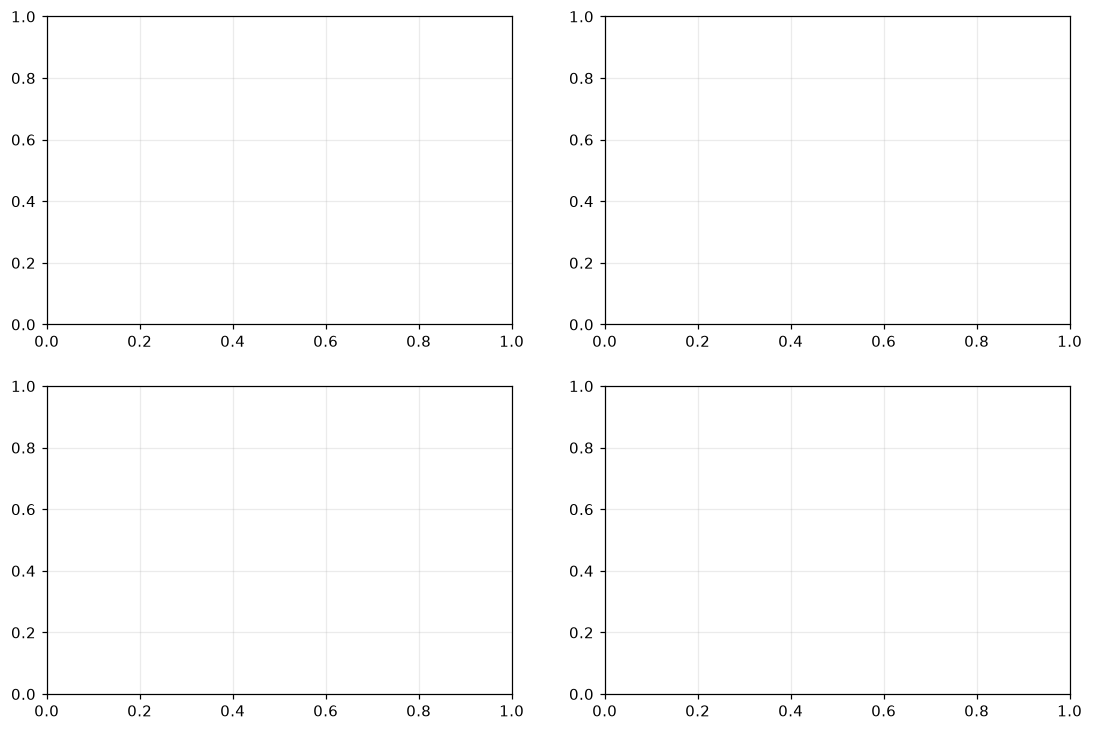

In [19]:
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

por_hora = df.groupby("hora_sal")["retraso15"].mean()
ax[0, 0].bar(por_hora.index, por_hora.values * 100, color="#2b6cb0")
ax[0, 0].set(title="Retraso según hora programada de salida", xlabel="hora", ylabel="% retrasados")

por_dia = df.groupby("dia_semana")["retraso15"].mean()
ax[0, 1].bar(["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"], por_dia.values * 100, color="#2b6cb0")
ax[0, 1].set(title="Retraso según día de la semana", ylabel="% retrasados")

por_aer = df.groupby("OP_UNIQUE_CARRIER", observed=True)["retraso15"].agg(["mean", "size"])
por_aer = por_aer[por_aer["size"] > 20_000].sort_values("mean")
ax[1, 0].barh(por_aer.index.astype(str), por_aer["mean"] * 100, color="#2b6cb0")
ax[1, 0].set(title="Retraso por aerolínea (> 20 mil vuelos)", xlabel="% retrasados")

con_prev = df[df.prev_disponible == 1]
cortes = pd.cut(con_prev["ret_prev_llegada"], [-61, -5, 0, 15, 30, 60, 361])
prop = con_prev.groupby(cortes, observed=True)["retraso15"].mean()
ax[1, 1].bar(range(len(prop)), prop.values * 100, color="#c05621")
ax[1, 1].set_xticks(range(len(prop)))
ax[1, 1].set_xticklabels([str(i) for i in prop.index], rotation=30, fontsize=8)
ax[1, 1].set(title="Propagación: retraso del tramo anterior (min)", ylabel="% retrasados")
plt.tight_layout()
guardar_fig(fig, "01_hipotesis_retraso")
plt.show()
print(f"Vuelos donde ya se conoce la llegada del tramo anterior: {df.prev_disponible.mean():.1%}")

### Faltantes: ¿cómo imputar `ret_prev_llegada`?
Faltan valores cuando el tramo anterior no existe, no se conoce o **aún no había aterrizado** a la hora de salida. Ese faltante **no es aleatorio**, por eso se conserva la bandera `prev_disponible`. Para el valor numérico se comparan cuatro opciones **ocultando a propósito el 25 % de los valores conocidos** y midiendo el error (MAE, en minutos) de cada una:

In [ ]:
base = df.loc[df.prev_disponible == 1].sample(min(60_000, int((df.prev_disponible == 1).sum())), random_state=SEMILLA).reset_index(drop=True)
if len(base) < 2_000:
    print("Muy pocos datos con tramo anterior conocido para el experimento.")
else:
    v = base["ret_prev_llegada"].to_numpy(dtype=float)
    oculto = rng.random(len(base)) < 0.25
    visto = ~oculto
    mae = {}
    mae["Media global"]   = mean_absolute_error(v[oculto], np.full(oculto.sum(), v[visto].mean()))
    mae["Mediana global"] = mean_absolute_error(v[oculto], np.full(oculto.sum(), np.median(v[visto])))

    med_hora = base.loc[visto].groupby("hora_sal")["ret_prev_llegada"].median()
    pred_grupo = base.loc[oculto, "hora_sal"].map(med_hora).fillna(np.median(v[visto])).to_numpy()
    mae["Mediana por hora de salida"] = mean_absolute_error(v[oculto], pred_grupo)

    auxiliares = ["hora_sal_dec", "DISTANCE", "holgura_prog", "vuelos_origen_hora", "dias_a_festivo", "tramo_del_dia", "dia_semana"]
    Xr = base[auxiliares].copy()
    Xr["aerolinea"] = base["OP_UNIQUE_CARRIER"].cat.codes
    reg = HistGradientBoostingRegressor(max_iter=100, random_state=SEMILLA).fit(Xr[visto], v[visto])
    mae["Regresión (HistGB)"] = mean_absolute_error(v[oculto], reg.predict(Xr[oculto]))

    comp = pd.Series(mae).sort_values().to_frame("MAE (min)")
    display(comp)
    mejor = comp.index[0]
    print(f"Mejor opción: {mejor}. Mejora frente a la mediana global: "
          f"{mae['Mediana global'] - comp.iloc[0,0]:.2f} min (desviación típica de la variable: {v.std():.1f} min).")
    comp.to_csv(RES / "comparacion_imputacion.csv")

**Decisión de imputación.** Dentro del `Pipeline` se usa la **mediana** (robusta a los retrasos extremos) junto con la bandera `prev_disponible`. La tabla de arriba muestra cuánto se ganaría con opciones más complejas; si la mejora es pequeña frente a la desviación de la variable, no justifica el costo de un imputador por regresión. ✍️ **Escriban aquí su lectura con los números de su corrida.**

### Demostración de fuga: qué pasa si dejamos entrar `DEP_DELAY`
`DEP_DELAY` (retraso de salida) solo se conoce cuando el avión ya salió, y casi determina el retraso de llegada. Se mide la diferencia de AUC con y sin esa columna:

In [ ]:
num_ok = ["DISTANCE", "CRS_ELAPSED_TIME", "hora_sal_dec", "hora_lleg", "dias_a_festivo", "vuelos_origen_hora",
          "vuelos_destino_hora", "tramo_del_dia", "holgura_prog", "ret_prev_llegada", "prev_disponible"]
demo = df.sample(min(80_000, len(df)), random_state=SEMILLA)
corte_demo = int(len(demo) * .7)
res_fuga = {}
for nombre, cols in {"Sin fuga (columnas legítimas)": num_ok, "CON fuga (+ DEP_DELAY)": num_ok + ["DEP_DELAY"]}.items():
    m = HistGradientBoostingClassifier(max_iter=100, random_state=SEMILLA)
    m.fit(demo[cols].iloc[:corte_demo], demo.retraso15.iloc[:corte_demo])
    res_fuga[nombre] = roc_auc_score(demo.retraso15.iloc[corte_demo:], m.predict_proba(demo[cols].iloc[corte_demo:])[:, 1])
display(pd.Series(res_fuga).to_frame("AUC"))
print("Si el AUC se dispara al meter DEP_DELAY, es la señal de la fuga: ese número NO se podría obtener en la vida real antes de que el avión salga.")

## 5 · Modelos

**Una sola vara para todos:** los mismos datos, la misma validación cruzada estratificada y el preprocesamiento **dentro del `Pipeline`** (la codificación por objetivo se ajusta solo con los datos de entrenamiento de cada pliegue, así no hay fuga entre pliegues).

**Partición temporal:** el último 15 % del tiempo queda como **prueba final** (nunca se toca para elegir modelo). Se entrena con el pasado y se evalúa con el futuro, como en la vida real.

In [ ]:
fechas_u = np.sort(df["fecha"].unique())
corte = fechas_u[int(len(fechas_u) * (1 - FRACCION_PRUEBA))]
entr_all = df.loc[df["fecha"] < corte]
test_all = df.loc[df["fecha"] >= corte]
print("Corte temporal:", pd.Timestamp(corte).date())
print(f"Entrenamiento disponible: {len(entr_all):,} vuelos ({entr_all.fecha.min().date()} → {entr_all.fecha.max().date()})")
print(f"Prueba final:             {len(test_all):,} vuelos ({test_all.fecha.min().date()} → {test_all.fecha.max().date()})")

NUM = ["DISTANCE", "CRS_ELAPSED_TIME", "hora_sal_dec", "hora_lleg", "dias_a_festivo", "vuelos_origen_hora",
       "vuelos_destino_hora", "tramo_del_dia", "holgura_prog", "ret_prev_llegada", "prev_disponible"]
CAT = ["OP_UNIQUE_CARRIER", "ORIGIN", "DEST", "dia_semana"]
PROHIBIDAS = {"DEP_DELAY", "ARR_DELAY", "ARR_DEL15", "retraso15", "fecha"}
assert not PROHIBIDAS & set(NUM + CAT), "¡Hay una columna con fuga en las variables!"

def armar_X(d):
    X = d[NUM + CAT].copy()
    for c in CAT:
        X[c] = X[c].astype(str)
    return X

muestra_final = entr_all.sample(min(N_FINAL, len(entr_all)), random_state=SEMILLA)
muestra_cv    = muestra_final.iloc[:min(N_CV, len(muestra_final))]       # la muestra de CV está dentro de la final
muestra_test  = test_all.sample(min(N_TEST, len(test_all)), random_state=SEMILLA)

X_cv, y_cv     = armar_X(muestra_cv),    muestra_cv["retraso15"].to_numpy()
X_fin, y_fin   = armar_X(muestra_final), muestra_final["retraso15"].to_numpy()
X_test, y_test = armar_X(muestra_test),  muestra_test["retraso15"].to_numpy()
print(f"\nMuestras → CV: {len(X_cv):,} · entrenamiento final: {len(X_fin):,} · prueba: {len(X_test):,}")
print(f"Tasa de retraso → CV {y_cv.mean():.2%} · final {y_fin.mean():.2%} · prueba {y_test.mean():.2%}")

### La regla a mano
Alguien sin ML diría: *«los vuelos que salen tarde en el día se retrasan»*. Se busca la hora de corte que mejor funciona **en entrenamiento** (una sola cifra que cualquiera puede aplicar):

In [ ]:
horas = np.arange(0, 24)
f1_reglas = [f1_score(y_fin, (X_fin["hora_sal_dec"].to_numpy() >= h).astype(int)) for h in horas]
HORA_REGLA = int(horas[int(np.argmax(f1_reglas))])
print(f"Regla a mano: «si el vuelo sale a las {HORA_REGLA}:00 o después, se retrasará»  (F1 en entrenamiento = {max(f1_reglas):.3f})")


class ReglaMano(BaseEstimator, ClassifierMixin):
    """Predice 'retrasado' si la hora programada de salida es >= hora."""
    def __init__(self, hora=16):
        self.hora = hora
    def fit(self, X, y):
        self.classes_ = np.array([0, 1])
        return self
    def predict_proba(self, X):
        p = (X["hora_sal_dec"].to_numpy() >= self.hora).astype(float)
        return np.c_[1 - p, p]
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] > 0.5).astype(int)

### Los modelos (familias distintas)
Línea base · regla a mano · **lineal** (regresión logística) · **árboles** (árbol, random forest) · **ensambles con boosting** (HistGradientBoosting, XGBoost) · **red neuronal** (MLP). Se descartó KNN y SVM con kernel: con cientos de miles de filas son demasiado lentos para una exposición en vivo y no aportan una familia nueva.

In [ ]:
def hacer_prep(escalar):
    num = [SimpleImputer(strategy="median")] + ([StandardScaler()] if escalar else [])
    return ColumnTransformer([("num", make_pipeline(*num), NUM),
                              ("cat", TargetEncoder(random_state=SEMILLA), CAT)])

# nombre: (modelo, ¿lleva preprocesamiento?, ¿escalar?, complejidad 1=simple … 8=compleja)
CATALOGO = {
    "Línea base (siempre a tiempo)": (DummyClassifier(strategy="prior"), False, False, 0),
    "Regla a mano":                  (ReglaMano(hora=HORA_REGLA),        False, False, 1),
    "Regresión logística":           (LogisticRegression(max_iter=500),  True,  True,  2),
    "Árbol de decisión":             (DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, random_state=SEMILLA), True, False, 3),
    "Random forest":                 (RandomForestClassifier(n_estimators=100, max_depth=14, min_samples_leaf=40, n_jobs=-1, random_state=SEMILLA), True, False, 5),
    "HistGradientBoosting":          (HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, random_state=SEMILLA), True, False, 6),
    "Red neuronal (MLP)":            (MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=60, random_state=SEMILLA), True, True, 7),
}
if HAY_XGB:
    CATALOGO["XGBoost"] = (XGBClassifier(n_estimators=250, max_depth=6, learning_rate=0.08, subsample=0.8,
                                         colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                                         eval_metric="logloss", random_state=SEMILLA), True, False, 8)

def construir(nombre):
    est, con_prep, escalar, _ = CATALOGO[nombre]
    return make_pipeline(hacer_prep(escalar), clone(est)) if con_prep else clone(est)

def umbral_f1(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.clip(pr + rc, 1e-12, None)
    i = int(np.nanargmax(f1[:-1])) if len(th) else 0
    return float(th[i]) if len(th) else 0.5

SIN_UMBRAL = {"Línea base (siempre a tiempo)", "Regla a mano"}   # sus predicciones ya son 0/1

def evaluar_cv(nombre, X, y):
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=SEMILLA)
    oof, aucs, aps = np.zeros(len(y)), [], []
    t0 = time.time()
    for tr, va in skf.split(X, y):
        m = construir(nombre).fit(X.iloc[tr], y[tr])          # misma validación para todos
        oof[va] = m.predict_proba(X.iloc[va])[:, 1]
        aucs.append(roc_auc_score(y[va], oof[va]))
        aps.append(average_precision_score(y[va], oof[va]))
    thr = 0.5 if nombre in SIN_UMBRAL else umbral_f1(y, oof)
    pred = (oof >= thr).astype(int) if nombre not in SIN_UMBRAL else (oof > 0.5).astype(int)
    return {"modelo": nombre, "AUC": np.mean(aucs), "AUC_std": np.std(aucs), "PR-AUC": np.mean(aps),
            "F1": f1_score(y, pred), "Recall": recall_score(y, pred), "Precisión": precision_score(y, pred, zero_division=0),
            "Exactitud": (pred == y).mean(), "umbral": thr, "seg": time.time() - t0}

print(f"Validación cruzada estratificada de {K_FOLDS} pliegues sobre {len(X_cv):,} vuelos de entrenamiento\n")
filas = []
for nombre in CATALOGO:
    r = evaluar_cv(nombre, X_cv, y_cv)
    filas.append(r)
    print(f"{nombre:<32} AUC {r['AUC']:.4f} ± {r['AUC_std']:.4f} · F1 {r['F1']:.3f} · {r['seg']:.0f} s")
tabla_cv = pd.DataFrame(filas).set_index("modelo").sort_values("AUC", ascending=False)
tabla_cv.to_csv(RES / "tabla_modelos_cv.csv")

## 6 · Evaluación

**Métricas** (la clase «retrasado» es la minoritaria, por eso la exactitud sola engaña): **AUC-ROC** (métrica principal, no depende del umbral), **PR-AUC**, y **F1/Recall/Precisión** con el umbral que maximiza F1 en validación.

In [ ]:
orden = tabla_cv[["AUC", "AUC_std", "PR-AUC", "F1", "Recall", "Precisión", "Exactitud", "seg"]]
display(orden)

fig, ax = plt.subplots(figsize=(8, 4.2))
t = tabla_cv.sort_values("AUC")
ax.barh(t.index, t["AUC"], xerr=t["AUC_std"], color="#2b6cb0")
ax.axvline(0.5, color="gray", ls="--")
ax.set(title=f"AUC en validación cruzada ({K_FOLDS} pliegues)", xlabel="AUC-ROC", xlim=(0.45, max(0.8, t["AUC"].max() + 0.03)))
plt.tight_layout()
guardar_fig(fig, "02_comparacion_modelos_cv")
plt.show()

### Elección del modelo
No siempre gana el número más alto. Regla de decisión (fijada **antes** de mirar la prueba): entre los modelos de ML cuyo AUC está **dentro de una desviación típica del mejor**, se elige **el más simple**.

In [ ]:
ml = tabla_cv.drop(index=["Línea base (siempre a tiempo)", "Regla a mano"])
mejor = ml["AUC"].idxmax()
margen = ml.loc[mejor, "AUC_std"]
candidatos = ml[ml["AUC"] >= ml.loc[mejor, "AUC"] - margen]
ELEGIDO = min(candidatos.index, key=lambda n: CATALOGO[n][3])
print(f"Mejor AUC: {mejor} ({ml.loc[mejor,'AUC']:.4f})  · margen (1 desv. típica): {margen:.4f}")
print("Dentro del margen:", list(candidatos.index))
print(f"\n➡️  Modelo elegido: {ELEGIDO}  (el más simple dentro del margen)")
UMBRAL = float(tabla_cv.loc[ELEGIDO, "umbral"])
print(f"Umbral de decisión (máx. F1 en validación): {UMBRAL:.3f}")

### Prueba final con datos del futuro (solo una vez)
Se entrena el elegido con la muestra final de entrenamiento y se evalúa en el último 15 % del tiempo, junto a la línea base y la regla a mano.

In [ ]:
archivo_modelo = MODELOS / "modelo_elegido.joblib"
t0 = time.time()
modelo = construir(ELEGIDO).fit(X_fin, y_fin)
print(f"{ELEGIDO} entrenado en {time.time()-t0:.0f} s con {len(X_fin):,} vuelos")
joblib.dump({"modelo": modelo, "nombre": ELEGIDO, "umbral": UMBRAL, "NUM": NUM, "CAT": CAT, "semilla": SEMILLA}, archivo_modelo)
print("Modelo guardado en:", archivo_modelo.relative_to(RAIZ))

p_test = modelo.predict_proba(X_test)[:, 1]
pred_test = (p_test >= UMBRAL).astype(int)
regla = ReglaMano(hora=HORA_REGLA).fit(X_fin, y_fin)
p_regla = regla.predict_proba(X_test)[:, 1]
pred_regla = (p_regla > 0.5).astype(int)

def fila(nombre, p, pred):
    return {"modelo": nombre, "AUC": roc_auc_score(y_test, p) if np.ptp(p) > 0 else 0.5,
            "PR-AUC": average_precision_score(y_test, p), "F1": f1_score(y_test, pred),
            "Recall": recall_score(y_test, pred), "Precisión": precision_score(y_test, pred, zero_division=0),
            "Exactitud": (pred == y_test).mean()}

tabla_test = pd.DataFrame([
    fila(ELEGIDO, p_test, pred_test),
    fila("Regla a mano", p_regla, pred_regla),
    fila("Línea base (siempre a tiempo)", np.full(len(y_test), y_fin.mean()), np.zeros(len(y_test), dtype=int)),
]).set_index("modelo")
tabla_test.to_csv(RES / "tabla_prueba_final.csv")
display(tabla_test)

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))

fpr, tpr, _ = roc_curve(y_test, p_test); fr, tr_, _ = roc_curve(y_test, p_regla)
ax[0].plot(fpr, tpr, label=f"{ELEGIDO} (AUC {tabla_test.loc[ELEGIDO,'AUC']:.3f})", color="#2b6cb0")
ax[0].plot(fr, tr_, label=f"Regla a mano (AUC {tabla_test.loc['Regla a mano','AUC']:.3f})", color="#c05621")
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set(title="Curva ROC (prueba temporal)", xlabel="falsos positivos", ylabel="verdaderos positivos"); ax[0].legend()

pr, rc, _ = precision_recall_curve(y_test, p_test)
ax[1].plot(rc, pr, color="#2b6cb0")
ax[1].axhline(y_test.mean(), color="gray", ls="--", label=f"azar = {y_test.mean():.2f}")
ax[1].set(title="Precisión–Recall", xlabel="recall", ylabel="precisión"); ax[1].legend()

cm = confusion_matrix(y_test, pred_test)
ax[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, f"{cm[i,j]:,}", ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
ax[2].set(title=f"Matriz de confusión (umbral {UMBRAL:.2f})", xticks=[0, 1], yticks=[0, 1],
          xticklabels=["a tiempo", "retrasado"], yticklabels=["a tiempo", "retrasado"], xlabel="predicho", ylabel="real")
ax[2].grid(False)
plt.tight_layout()
guardar_fig(fig, "03_evaluacion_prueba_final")
plt.show()

### ¿Qué columnas pesan más? (importancia por permutación)
Se barajan las columnas de a una en la prueba y se mide cuánto cae el AUC: cuanto más cae, más usa el modelo esa columna.

In [ ]:
sub = np.random.default_rng(SEMILLA).choice(len(X_test), size=min(20_000, len(X_test)), replace=False)
imp = permutation_importance(modelo, X_test.iloc[sub], y_test[sub], scoring="roc_auc",
                            n_repeats=3, random_state=SEMILLA, n_jobs=1)
importancias = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(importancias.index, importancias.values, color="#2b6cb0")
ax.set(title="Caída del AUC al barajar cada columna", xlabel="caída del AUC")
plt.tight_layout()
guardar_fig(fig, "04_importancia_columnas")
plt.show()
importancias.sort_values(ascending=False).to_csv(RES / "importancia_columnas.csv", header=["caida_AUC"])

### ¿En qué casos falla? (AUC por franja horaria de salida)

In [ ]:
t = muestra_test[["hora_sal"]].copy()
t["y"], t["p"] = y_test, p_test
t["franja"] = pd.cut(t["hora_sal"], [-1, 5, 11, 17, 23], labels=["madrugada (0–5)", "mañana (6–11)", "tarde (12–17)", "noche (18–23)"])
def auc_seguro(g):
    return roc_auc_score(g.y, g.p) if g.y.nunique() == 2 else np.nan
por_franja = t.groupby("franja", observed=True).apply(lambda g: pd.Series({
    "vuelos": len(g), "tasa real": g.y.mean(), "tasa predicha": g.p.mean(), "AUC": auc_seguro(g)}))
display(por_franja)
por_franja.to_csv(RES / "error_por_franja.csv")

### Resumen para la exposición

In [7]:
resumen = {
    "problema": f"Retraso de llegada ≥ {UMBRAL_RETRASO} min, predicho a la salida programada",
    "periodo": f"{DESDE} a {HASTA}", "filas_totales": int(len(df)), "modo_rapido": MODO_RAPIDO,
    "semilla": SEMILLA, "modelo_elegido": ELEGIDO, "umbral": UMBRAL, "regla_a_mano_hora": HORA_REGLA,
    "AUC_prueba_modelo": float(tabla_test.loc[ELEGIDO, "AUC"]),
    "AUC_prueba_regla": float(tabla_test.loc["Regla a mano", "AUC"]),
    "F1_prueba_modelo": float(tabla_test.loc[ELEGIDO, "F1"]),
    "F1_prueba_regla": float(tabla_test.loc["Regla a mano", "F1"]),
}
(RES / "resumen_final.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False))

NameError: name 'UMBRAL_RETRASO' is not defined

### Conclusiones  ✍️ (escríbanlas con los números de su corrida)

1. **¿ML valió la pena?** Comparen el AUC y el F1 del modelo elegido contra la regla a mano y la línea base en la tabla de la prueba final.
2. **¿Qué modelo se eligió y por qué?** Citen los modelos que quedaron dentro del margen de una desviación típica y por qué ganó el más simple.
3. **¿Qué columnas pesan más?** Vean la gráfica de importancia: ¿pesa más la propagación (`ret_prev_llegada`) o el calendario?
4. **¿Dónde falla?** Revisen la tabla por franja horaria.
5. **Límites:** no hay clima, no hay información de tráfico aéreo en tiempo real y se predice solo con lo conocido a la salida programada. Un modelo con `DEP_DELAY` sería mucho más preciso, pero sería fuga.